# 01 — Setup, product selection and first map

**Goal:** go from "a NISAR granule name" to "I can see this scene on a map", and register the
choice in a session file that every later notebook reads.

This series follows the structure of the open NISAR GCOV training toolkit of D. K. Pandey
(`dharmendraisro/nisar-polarimetric-training`, Apache-2.0) and adapts it to what is actually
acquired over Europe: **NISAR L-band dual-pol HH/HV** (no quad-pol, no S-band), compared with
**Sentinel-1 C-band VV/VH**, on the Vosges clear-cut site of this feasibility study.
All code used here lives in the `nisar_s1` package of this repository, so it can be reused outside
the notebooks (and on ROSE-L L2 products, expected to share the same geocoded layout).

**Data are never stored in the repository.** They go to `data_dir` (see `notebooks/kit_config.yaml`).
Earthdata credentials are read from `~/.netrc` by `earthaccess` and are never printed.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from nisar_s1.config import load_kit
from nisar_s1 import product as P

kit = load_kit()                                  # notebooks/kit_config.yaml
OUT = Path(kit["data_dir"]) / "outputs" / "01"   # outputs stay outside the repository
OUT.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 90, "axes.spines.top": False, "axes.spines.right": False})

## 01A — Which NISAR products cover the area of interest?

The search uses the ASF catalogue (no login needed for searching). We list the GCOV granules
(L2, geocoded, radiometrically terrain-corrected covariance) over the AOI.

In [2]:
from nisar_s1.config import bbox_to_wkt
from nisar_s1.search import search_nisar

bbox = kit["aoi"]["bbox_wgs84"]
try:
    found = search_nisar(bbox_to_wkt(bbox), "2026-06-01", "2026-11-30", product_types=("GCOV",))
    cols = ["sceneName", "track", "direction", "frame", "bw_code", "pol_code", "ref_date", "size_mb"]
    gcov_list = found[[c for c in cols if c in found]].sort_values("ref_date")
    print(len(gcov_list), "GCOV granules over the AOI")
    display(gcov_list.groupby(["track", "direction", "frame", "bw_code"]).size().rename("n").reset_index())
except Exception as e:  # offline: the rest of the notebook works with the configured granule
    gcov_list = None
    print("catalogue search not available:", type(e).__name__, e)

48 GCOV granules over the AOI


,track,direction,frame,bw_code,n
0,66,D,64,2005,12
1,72,A,26,2005,12
2,138,D,64,2005,12
3,144,A,26,2005,12


The training granule is fixed in `kit_config.yaml` so that everybody works on the same scene:
track 144 ascending, frame 26, 20+5 MHz mode (`2005`), dual-pol `DHDH`, 3 November 2026.
The notebooks open the **local copy** if it has been downloaded, otherwise they **stream** the file
from ASF (only the HDF5 chunks that are read are transferred).

In [3]:
g = kit["gcov"]
local = Path(g["local"])
print("granule :", g["granule"])
print("local   :", local, "->", f"{local.stat().st_size / 2**30:.2f} GB" if local.exists() else "absent (will stream)")
print("netrc   :", "present" if (Path.home() / ".netrc").exists() else "MISSING (needed to stream from ASF)")

granule : NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001
local   : /media/dell/Transcend1/nisar_data/kit/gcov/NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5 -> 1.95 GB
netrc   : present


## 01B — Footprint from the product itself

opening local file: NISAR_L2_PR_GCOV_034_144_A_026_2005_DHDH_M_20261103T041937_20261103T042013_P05036_N_F_J_001.h5
GCOV LSAR Ascending track 144 frame 26
start: 2026-11-03T04:19:37.000000000


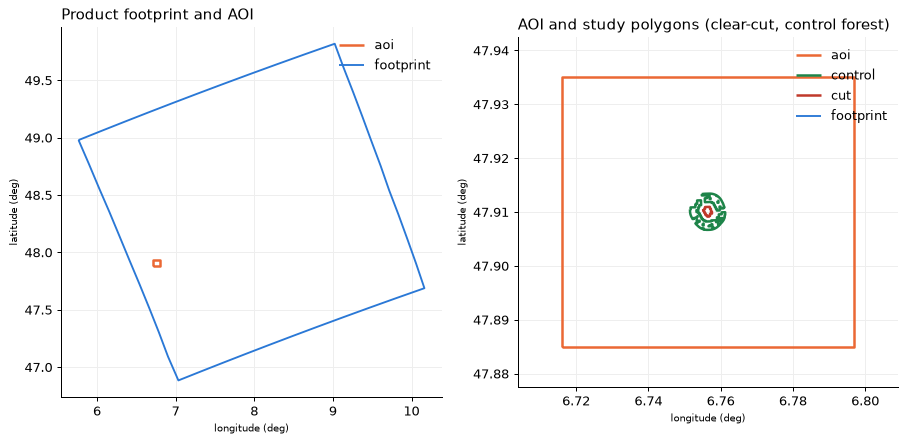

In [4]:
from nisar_s1 import maps
import geopandas as gpd

with P.open_local_or_remote(g["local"], g["url"]) as h5:
    prof = P.product_profile(h5)
    footprint = P.footprint_lonlat(h5)
sites = gpd.read_file(kit["aoi"]["site_polygons"])
layers = maps.layers_frame(footprint, bbox, sites)
print(prof.product_type, prof.band, prof.orbit_direction, "track", prof.track, "frame", prof.frame)
print("start:", prof.start)

fig, axs = plt.subplots(1, 2, figsize=(12, 5.5))
maps.static_map(layers[layers.layer.isin(["footprint", "aoi"])], "Product footprint and AOI", ax=axs[0])
maps.static_map(layers, "AOI and study polygons (clear-cut, control forest)", ax=axs[1], zoom_to="aoi")
fig.savefig(OUT / "01_footprint.png", dpi=120, bbox_inches="tight")
plt.show()

Interactive version (OpenStreetMap background; the static map above is the one that must work offline):

In [5]:
maps.folium_map(layers, zoom_to="aoi")

## 01C — Register the choice in the session file

In [6]:
session = P.save_session(kit["session_file"], granule=g["granule"], gcov_local=g["local"], gcov_url=g["url"],
                         product_type=prof.product_type, epsg_hint=prof.grids["frequencyA"].epsg)
print(kit["session_file"])

/media/dell/Transcend1/nisar_data/kit/session.json


### Checkpoint
Where is the scene (country, region)? Which orbit direction and track? Which projection (EPSG code)
is the product delivered in? You will need that EPSG code in notebooks 06 and 10.

In [7]:
checks = {
    "product is a GCOV": prof.product_type == "GCOV",
    "AOI inside the footprint": footprint.contains(layers[layers.layer == 'aoi'].geometry.iloc[0]),
    "session saved": Path(kit["session_file"]).exists(),
}
for k, v in checks.items():
    print(f"  [{'x' if v else ' '}] {k}")
assert all(checks.values()), "some checks failed: read the messages above"
print("Module 01 STATUS: PASS")

  [x] product is a GCOV
  [x] AOI inside the footprint
  [x] session saved
Module 01 STATUS: PASS
